<a href="https://colab.research.google.com/github/Stongef/DL-2/blob/main/CV_Odev_Pet_ResNet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision Ödevi – Evcil Hayvan Irkı Sınıflandırma (Oxford-IIIT Pet + ResNet-50)

**Çalıştırma:** Colab'de `Çalışma zamanı > Çalışma zamanı türünü değiştir > T4 GPU` seçip hücreleri sırayla çalıştır.

| Alan | Değer |
|---|---|
| Görev | Görüntü sınıflandırma (37 sınıf) |
| Veri seti | Oxford-IIIT Pet |
| Model | ResNet-50 (ImageNet ön eğitimli, transfer learning) |

In [19]:
!pip -q install gradio scikit-learn seaborn

## 1. Kurulum ve ayarlar

In [20]:
import time, json, random
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# --- Hiperparametreler ---
BATCH_SIZE   = 32
EPOCHS       = 8
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
VAL_RATIO    = 0.2
IMG_SIZE     = 224

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "GPU yok (eğitim yavaş olur)")

Cihaz: cuda | Tesla T4


## 2. Veri seti ve train / validation / test ayrımı
Oxford-IIIT Pet'in resmi `trainval` kümesi (3680 görüntü) %80 train / %20 validation olarak bölünür, resmi `test` kümesi (3669 görüntü) en sonda tek seferlik değerlendirme için ayrılır.

In [21]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet istatistikleri

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

ROOT = "./data"
trainval_aug  = OxfordIIITPet(ROOT, split="trainval", target_types="category", transform=train_tf, download=True)
trainval_eval = OxfordIIITPet(ROOT, split="trainval", target_types="category", transform=eval_tf)
test_ds       = OxfordIIITPet(ROOT, split="test",     target_types="category", transform=eval_tf, download=True)

class_names = trainval_aug.classes
NUM_CLASSES = len(class_names)

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(trainval_aug), generator=g).tolist()
n_val = int(VAL_RATIO * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_ds = Subset(trainval_aug,  train_idx)   # augmentation'lı
val_ds   = Subset(trainval_eval, val_idx)     # augmentation'sız

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Sınıf sayısı: {NUM_CLASSES}")
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

Sınıf sayısı: 37
Train: 2944 | Val: 736 | Test: 3669


## 3. Model, loss ve optimizer

In [22]:
model = resnet50(weights=ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)   # 1000 -> 37 sınıf
model = model.to(device)

criterion = nn.CrossEntropyLoss()                         # softmax + NLL (çıkışta logit verilir)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print("Toplam parametre:", f"{sum(p.numel() for p in model.parameters()):,}")

Toplam parametre: 23,583,845


## 4. Eğitim

In [23]:
def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            count += x.size(0)
    return total_loss / count, correct / count

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader,   train=False)
    scheduler.step()
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}")

train_time = time.time() - t0
model.load_state_dict(best_state)
print(f"\nEn iyi val accuracy: {best_val_acc:.4f} | Toplam eğitim süresi: {train_time/60:.1f} dk")

Epoch 01/8 | train loss 2.0334 acc 0.630 | val loss 0.4447 acc 0.894
Epoch 02/8 | train loss 0.3283 acc 0.925 | val loss 0.2803 acc 0.929
Epoch 03/8 | train loss 0.1570 acc 0.961 | val loss 0.2217 acc 0.933
Epoch 04/8 | train loss 0.0956 acc 0.975 | val loss 0.1828 acc 0.944
Epoch 05/8 | train loss 0.0630 acc 0.987 | val loss 0.1978 acc 0.940
Epoch 06/8 | train loss 0.0504 acc 0.989 | val loss 0.1649 acc 0.948
Epoch 07/8 | train loss 0.0326 acc 0.996 | val loss 0.1747 acc 0.946
Epoch 08/8 | train loss 0.0340 acc 0.995 | val loss 0.1744 acc 0.951

En iyi val accuracy: 0.9511 | Toplam eğitim süresi: 5.5 dk


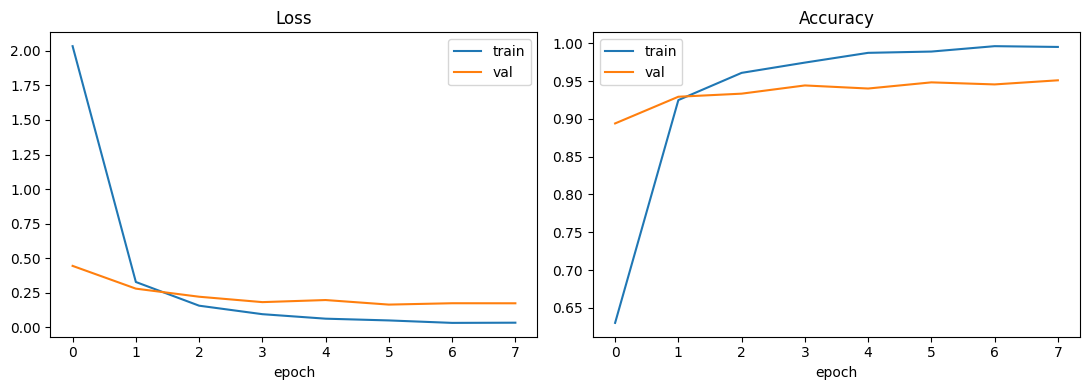

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("egitim_egrileri.png", dpi=150); plt.show()

## 5. Performans değerlendirmesi (test kümesi)

In [25]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

acc = accuracy_score(y_true, y_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

print(f"Accuracy          : {acc:.4f}")
print(f"Macro    P / R / F1: {p_m:.4f} / {r_m:.4f} / {f_m:.4f}")
print(f"Weighted P / R / F1: {p_w:.4f} / {r_w:.4f} / {f_w:.4f}")
print()
print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))

Accuracy          : 0.9193
Macro    P / R / F1: 0.9212 / 0.9187 / 0.9179
Weighted P / R / F1: 0.9223 / 0.9193 / 0.9187

                            precision    recall  f1-score   support

                Abyssinian      0.892     0.929     0.910        98
          American Bulldog      0.730     0.920     0.814       100
 American Pit Bull Terrier      0.775     0.620     0.689       100
              Basset Hound      1.000     0.930     0.964       100
                    Beagle      0.913     0.940     0.926       100
                    Bengal      0.763     0.900     0.826       100
                    Birman      0.795     0.890     0.840       100
                    Bombay      0.813     0.989     0.892        88
                     Boxer      0.920     0.929     0.925        99
         British Shorthair      0.952     0.800     0.870       100
                 Chihuahua      0.922     0.940     0.931       100
              Egyptian Mau      0.889     0.907     0.898      

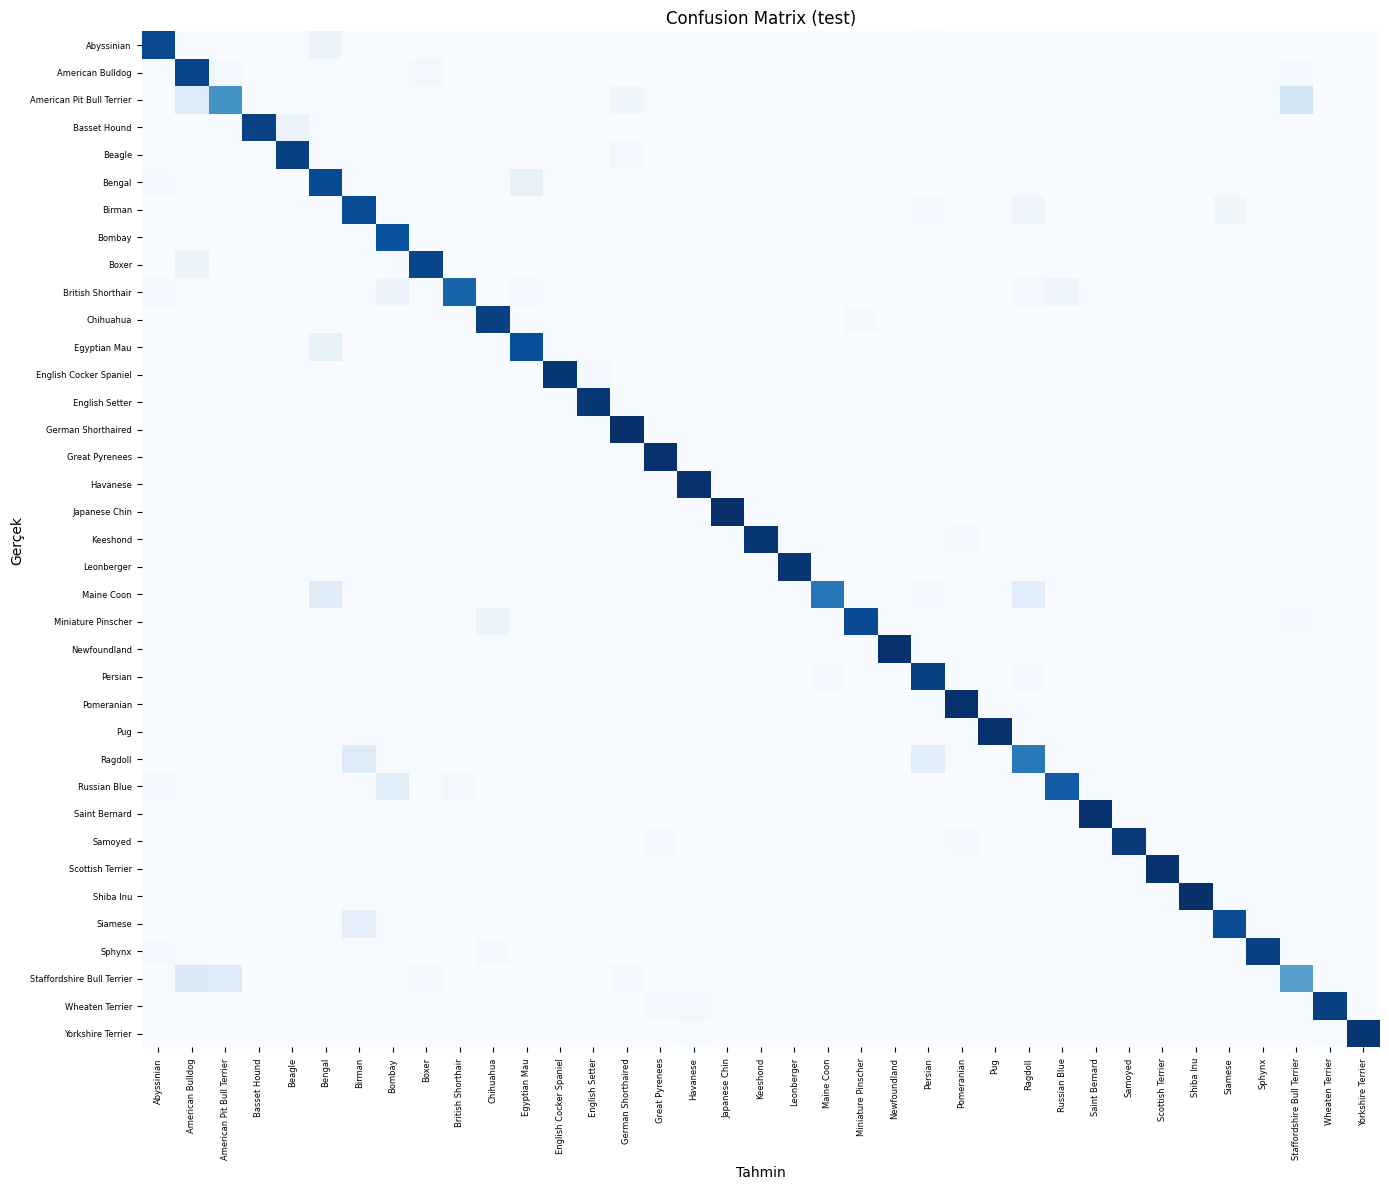

En çok karıştırılan 5 çift (gerçek -> tahmin : adet)
  American Pit Bull Terrier -> Staffordshire Bull Terrier : 19
  Staffordshire Bull Terrier -> American Bulldog : 14
  Ragdoll -> Birman : 13
  American Pit Bull Terrier -> American Bulldog : 13
  Staffordshire Bull Terrier -> American Pit Bull Terrier : 13


In [26]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title("Confusion Matrix (test)")
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

# En çok karıştırılan sınıf çiftleri (raporda yorum için kullanışlı)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
print("En çok karıştırılan 5 çift (gerçek -> tahmin : adet)")
for i, j in pairs:
    print(f"  {class_names[i]} -> {class_names[j]} : {cm_off[i, j]}")

In [27]:
# Tahmin (inference) süresi: tek görüntü, 100 tekrar ortalaması
x1 = test_ds[0][0].unsqueeze(0).to(device)
with torch.no_grad():
    for _ in range(10): model(x1)                      # ısınma
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(100): model(x1)
    if device.type == "cuda": torch.cuda.synchronize()
inference_ms = (time.time() - t0) / 100 * 1000
print(f"Tek görüntü tahmin süresi: {inference_ms:.1f} ms ({device.type})")

Tek görüntü tahmin süresi: 8.2 ms (cuda)


In [28]:
# Rapor tablosu için özet
print("=== RAPOR TABLOSU İÇİN ÖZET ===")
print(f"Input Size        : {IMG_SIZE}x{IMG_SIZE}x3")
print(f"Hyperparameters   : lr={LEARNING_RATE}, batch={BATCH_SIZE}, epochs={EPOCHS}, weight_decay={WEIGHT_DECAY}, cosine LR schedule")
print("Optimizer         : AdamW")
print("Activation/Output : ReLU (ResNet blokları) / Softmax (CrossEntropyLoss içinde)")
print("Loss              : CrossEntropyLoss")
print(f"Best Performance  : test acc {acc:.4f}, macro F1 {f_m:.4f} (best val acc {best_val_acc:.4f})")
print(f"Training time     : {train_time/60:.1f} dk")
print(f"Inference Time    : {inference_ms:.1f} ms/görüntü ({device.type})")
print("Training Env      :", torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU', "| Google Colab | PyTorch", torch.__version__)

=== RAPOR TABLOSU İÇİN ÖZET ===
Input Size        : 224x224x3
Hyperparameters   : lr=0.0001, batch=32, epochs=8, weight_decay=0.0001, cosine LR schedule
Optimizer         : AdamW
Activation/Output : ReLU (ResNet blokları) / Softmax (CrossEntropyLoss içinde)
Loss              : CrossEntropyLoss
Best Performance  : test acc 0.9193, macro F1 0.9179 (best val acc 0.9511)
Training time     : 5.5 dk
Inference Time    : 8.2 ms/görüntü (cuda)
Training Env      : Tesla T4 | Google Colab | PyTorch 2.14.1+cu130


## 6. Modeli kaydet

In [29]:
torch.save(model.state_dict(), "pet_resnet50.pth")
with open("classes.json", "w") as f:
    json.dump(class_names, f)

from google.colab import files
files.download("pet_resnet50.pth"); files.download("classes.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Uygulama (Gradio)

In [30]:
import gradio as gr

def predict(img):
    if img is None:
        return None
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    return {class_names[i]: float(probs[i]) for i in range(NUM_CLASSES)}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Bir kedi/köpek fotoğrafı yükle"),
    outputs=gr.Label(num_top_classes=5, label="Tahmin"),
    title="Evcil Hayvan Irkı Sınıflandırıcı (ResNet-50)",
    description="Oxford-IIIT Pet veri setiyle eğitilmiş 37 sınıflı model.",
)
demo.launch(share=True)   # çıkan public linkle kendi telefonundan da deneyebilirsin

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d1910349955308ea2e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8. Gerçek görüntülerle test
1. Aşağıdaki hücreyi çalıştır, telefonunla çektiğin **5 fotoğrafı** yükle.
2. `TRUE_LABELS` sözlüğüne her dosya adı için gerçek ırkı yaz (sınıf listesi için bir önceki bölümdeki `class_names` çıktısına bak; bilmiyorsan "kedi (ırkı bilinmiyor)" gibi yaz).

In [31]:
from google.colab import files
from PIL import Image
import io

uploaded = files.upload()
print(list(uploaded.keys()))

Saving maya5.jpeg to maya5 (1).jpeg
Saving maya4.jpeg to maya4 (1).jpeg
Saving maya3.jpeg to maya3 (1).jpeg
Saving maya2.jpeg to maya2 (1).jpeg
Saving maya1.jpeg to maya1.jpeg
['maya5 (1).jpeg', 'maya4 (1).jpeg', 'maya3 (1).jpeg', 'maya2 (1).jpeg', 'maya1.jpeg']


maya5 (1).jpeg -> British Shorthair 99.8%, Russian Blue 0.1%, Siamese 0.0% | gerçek: ?
maya4 (1).jpeg -> British Shorthair 79.5%, Russian Blue 16.2%, Bombay 1.3% | gerçek: ?
maya3 (1).jpeg -> British Shorthair 93.6%, Russian Blue 4.6%, Bombay 0.2% | gerçek: ?
maya2 (1).jpeg -> British Shorthair 99.5%, Russian Blue 0.3%, Maine Coon 0.1% | gerçek: ?
maya1.jpeg -> British Shorthair 97.4%, Russian Blue 0.9%, Bombay 0.3% | gerçek: ?


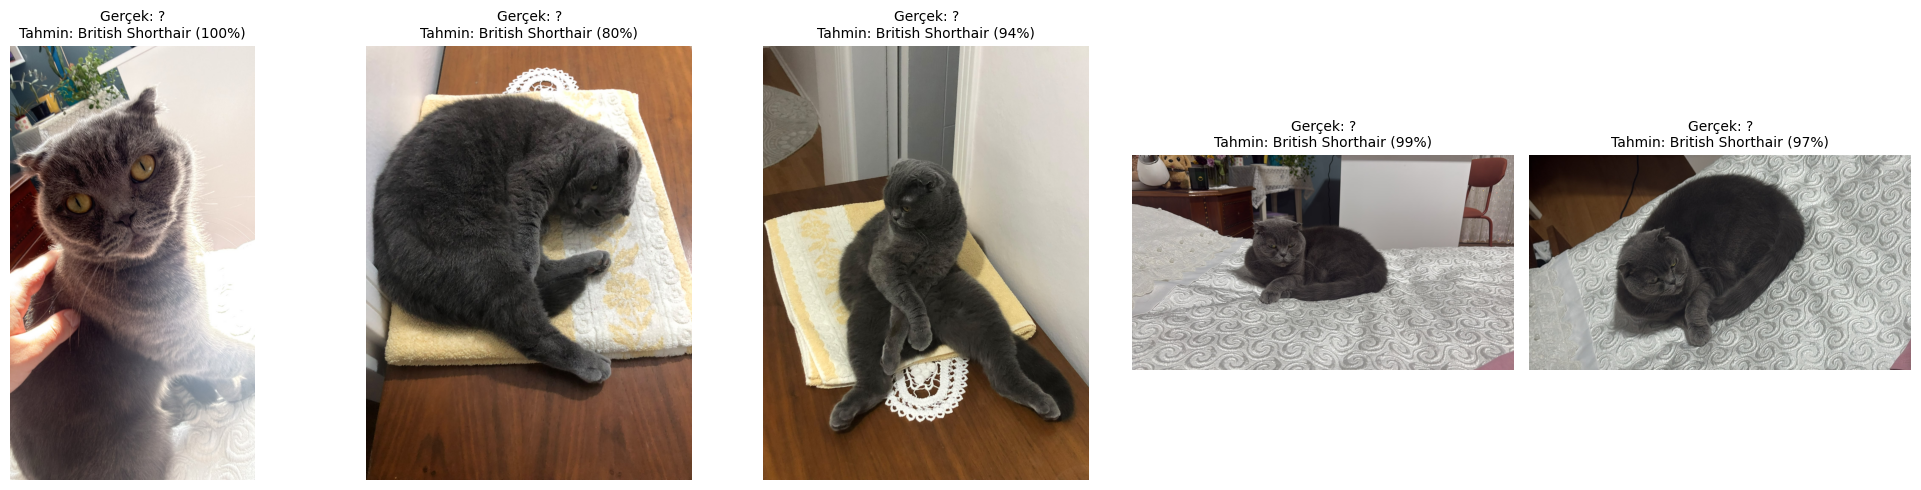

In [32]:
# >>> Dosya adlarını ve gerçek etiketleri kendine göre düzenle <<<
TRUE_LABELS = {
    # "foto1.jpg": "Bengal",
    # "foto2.jpg": "pug",
}

names = list(uploaded.keys())[:5]
fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 5))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, names):
    img = Image.open(io.BytesIO(uploaded[name])).convert("RGB")
    probs = predict(img)
    top3 = sorted(probs.items(), key=lambda kv: -kv[1])[:3]
    ax.imshow(img); ax.axis("off")
    truth = TRUE_LABELS.get(name, "?")
    ax.set_title(f"Gerçek: {truth}\nTahmin: {top3[0][0]} ({top3[0][1]*100:.0f}%)", fontsize=10)
    print(name, "->", ", ".join(f"{c} {p*100:.1f}%" for c, p in top3), "| gerçek:", truth)
plt.tight_layout(); plt.savefig("gercek_test.png", dpi=150); plt.show()